# Logistic Regression – Diabetes Prediction

## Project: Diabetes Prediction using Kaggle Data

**Student:** Beeresh R  
**Dataset:** Pima Indians Diabetes Database  
**Model:** Logistic Regression

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("diabetes.csv")

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 768
Number of columns: 9


In [4]:
print(df.columns.tolist())

['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


## Dataset Understanding

The Pima Indians Diabetes Dataset contains information about patients and is used to predict whether a patient has diabetes.

The target variable is **Outcome**:

- 0 = No Diabetes
- 1 = Diabetes

The predictor variables are Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, and Age.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(4), int64(5)
memory usage: 54.1 KB


In [6]:
print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [7]:
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for col in zero_columns:
    print(col, ":", (df[col] == 0).sum())

Glucose : 0
BloodPressure : 0
SkinThickness : 0
Insulin : 0
BMI : 0


In [8]:
print("Dataset shape:")
print(df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nBasic statistics:")
display(df.describe())

Dataset shape:
(768, 9)

First 5 rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1



Basic statistics:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.677083,72.389323,29.089844,141.753906,32.434635,0.471876,33.240885,0.348958
std,3.369578,30.464161,12.106039,8.890820,89.100847,6.880498,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,102.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,28.000000,102.500000,32.050000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,169.500000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [9]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [10]:
cleaned_df = df.copy()

print("Missing values before cleaning:")
print(cleaned_df.isnull().sum().sum())

print("\nDuplicate rows before cleaning:")
print(cleaned_df.duplicated().sum())

Missing values before cleaning:
0

Duplicate rows before cleaning:
0


In [11]:
print("Outcome distribution:")
print(df["Outcome"].value_counts())

print("\nOutcome percentage:")
print(df["Outcome"].value_counts(normalize=True) * 100)

Outcome distribution:
Outcome
0    500
1    268
Name: count, dtype: int64

Outcome percentage:
Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


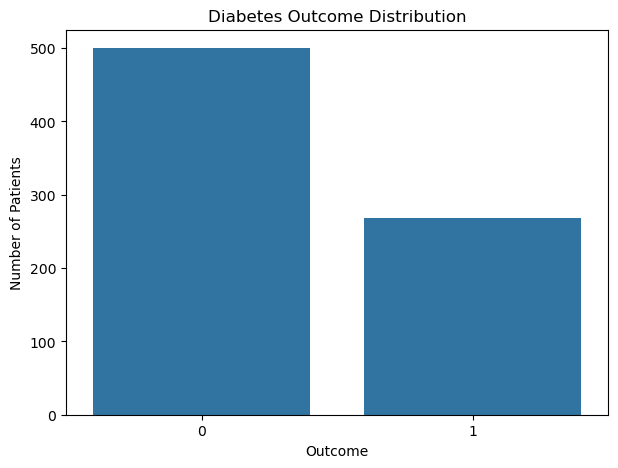

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Outcome")

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome")
plt.ylabel("Number of Patients")

plt.show()

### Observation

The dataset contains more patients without diabetes than patients with diabetes. Therefore, the two outcome classes are not perfectly balanced.

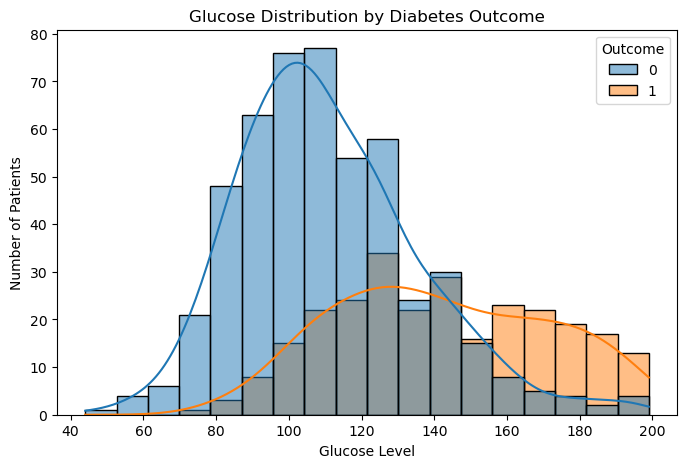

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Glucose", hue="Outcome", kde=True)

plt.title("Glucose Distribution by Diabetes Outcome")
plt.xlabel("Glucose Level")
plt.ylabel("Number of Patients")

plt.show()

### Observation

Patients with diabetes generally show higher glucose levels compared with patients without diabetes. This indicates that Glucose can be an important predictor of diabetes.

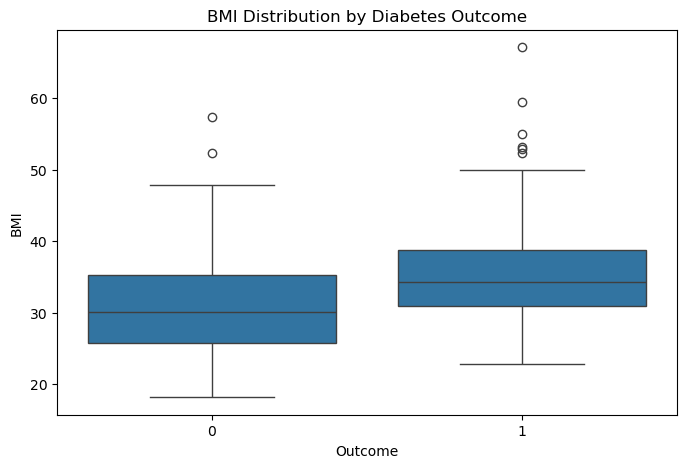

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Outcome", y="BMI")

plt.title("BMI Distribution by Diabetes Outcome")
plt.xlabel("Outcome")
plt.ylabel("BMI")

plt.show()

### Observation

The BMI distribution differs between the two outcome groups. Patients with diabetes tend to have higher BMI values, although there is considerable overlap between the groups.

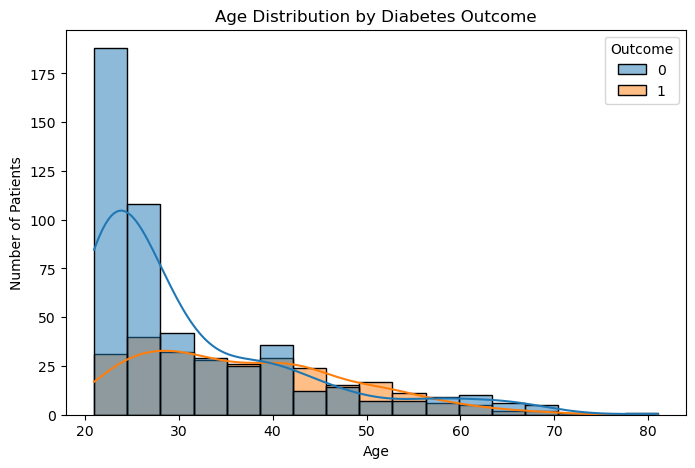

In [15]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", hue="Outcome", kde=True)

plt.title("Age Distribution by Diabetes Outcome")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.show()

### Observation

Diabetes outcomes are observed across different age groups, with older patients generally showing a higher tendency toward diabetes.

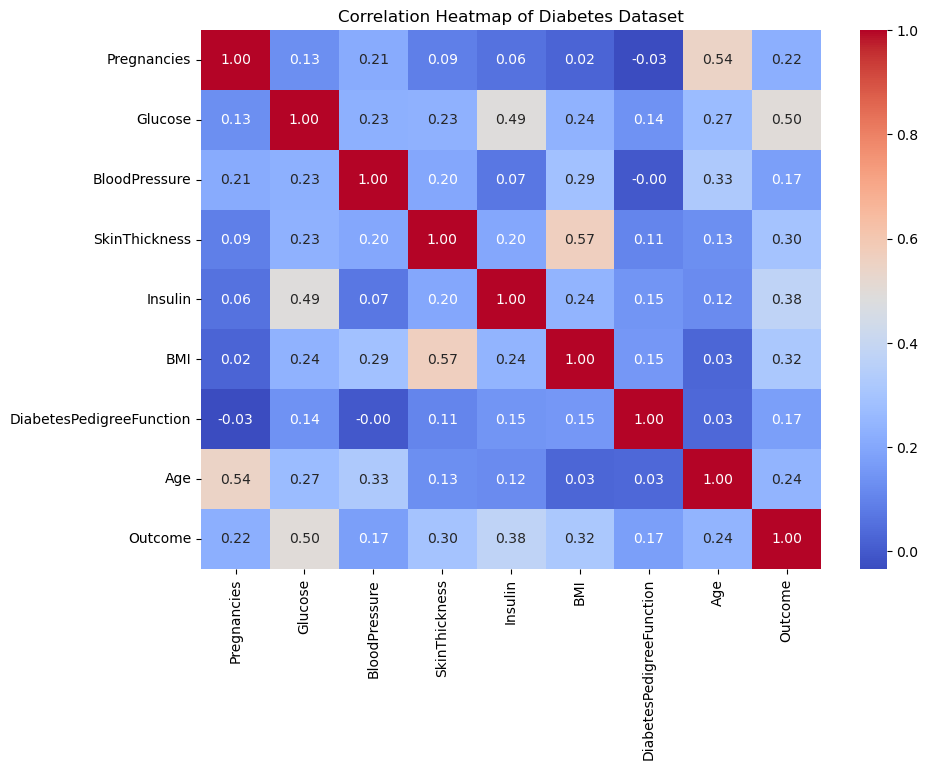

In [16]:
plt.figure(figsize=(10, 7))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Diabetes Dataset")
plt.show()

### Observation

Glucose generally has a noticeable positive relationship with the diabetes Outcome. Other variables such as BMI, Age and Pregnancies also show relationships with the target variable.

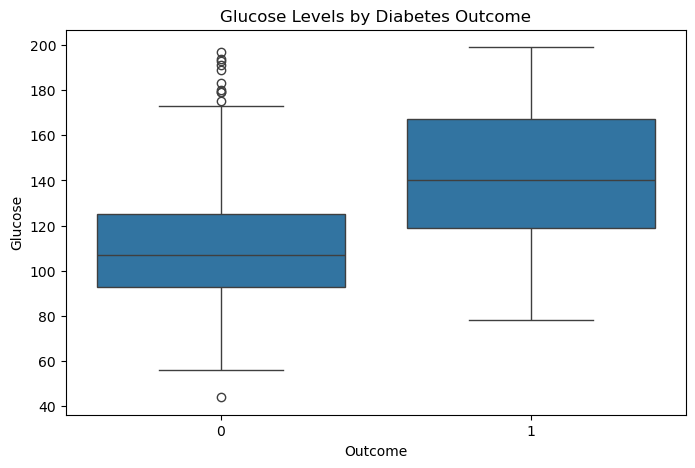

In [17]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Outcome", y="Glucose")

plt.title("Glucose Levels by Diabetes Outcome")
plt.xlabel("Outcome")
plt.ylabel("Glucose")

plt.show()

### Observation

Patients with diabetes generally have higher glucose levels. This makes Glucose one of the important variables for diabetes prediction.

In [18]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (768, 8)
Target shape: (768,)


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


In [20]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

print("Missing values handled using median imputation.")

Missing values handled using median imputation.


In [21]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Feature scaling completed.")

Feature scaling completed.


In [22]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [23]:
y_pred = model.predict(X_test_scaled)

print("Predictions completed.")
print("First 10 predictions:")
print(y_pred[:10])

Predictions completed.
First 10 predictions:
[0 0 0 0 0 0 1 1 0 1]


In [24]:
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("First 10 predicted probabilities:")
print(y_prob[:10])

First 10 predicted probabilities:
[0.47739551 0.07407477 0.37011559 0.33773074 0.03196289 0.10346784
 0.55984821 0.90195873 0.0672363  0.9042001 ]


In [25]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))

Accuracy: 0.7078


In [26]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

Precision: 0.5882
Recall: 0.5556
F1 Score: 0.5714


In [27]:
roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", round(roc_auc, 4))

ROC-AUC Score: 0.8263


In [28]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.79      0.78       100
           1       0.59      0.56      0.57        54

    accuracy                           0.71       154
   macro avg       0.68      0.67      0.67       154
weighted avg       0.70      0.71      0.71       154



In [29]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[79 21]
 [24 30]]


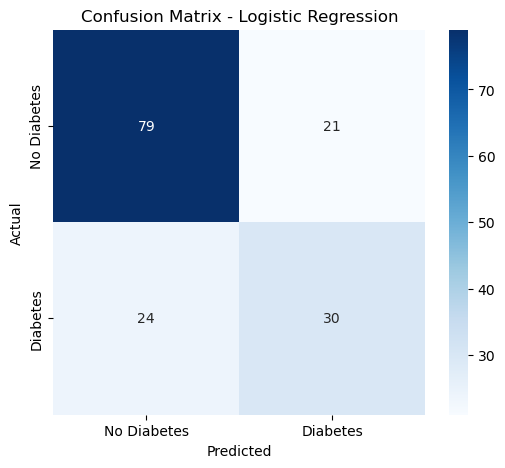

In [30]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

### Observation

The confusion matrix shows the number of correctly and incorrectly classified patients. The model correctly identifies many patients in both outcome classes, while some patients are misclassified.

In [31]:
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

results["Score"] = results["Score"].round(4)

display(results)

,Metric,Score
0,Accuracy,0.7078
1,Precision,0.5882
2,Recall,0.5556
3,F1 Score,0.5714
4,ROC-AUC,0.8263


In [32]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

display(comparison.head(20))

,Actual,Predicted
0,0,0
1,0,0
2,0,0
3,1,0
4,0,0
5,0,0
6,1,1
7,1,1
8,0,0
9,0,1


In [33]:
new_patient = pd.DataFrame({
    "Pregnancies": [2],
    "Glucose": [120],
    "BloodPressure": [70],
    "SkinThickness": [30],
    "Insulin": [100],
    "BMI": [32.0],
    "DiabetesPedigreeFunction": [0.5],
    "Age": [35]
})

new_patient_imputed = imputer.transform(new_patient)
new_patient_scaled = scaler.transform(new_patient_imputed)

prediction = model.predict(new_patient_scaled)[0]
probability = model.predict_proba(new_patient_scaled)[0][1]

print("Predicted Outcome:", prediction)
print("Probability of Diabetes:", round(probability, 4))

if prediction == 1:
    print("Prediction: Diabetes")
else:
    print("Prediction: No Diabetes")

Predicted Outcome: 0
Probability of Diabetes: 0.2008
Prediction: No Diabetes


In [34]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

display(coefficients)

,Feature,Coefficient
1,Glucose,0.934942
4,Insulin,0.614170
5,BMI,0.466051
0,Pregnancies,0.337228
3,SkinThickness,0.294976
6,DiabetesPedigreeFunction,0.174725
7,Age,0.159826
2,BloodPressure,-0.004245


### Observation

The coefficient plot shows the contribution of each predictor to the Logistic Regression model. Positive coefficients increase the model's tendency toward the diabetes class, while negative coefficients decrease it.

# Conclusion

The Pima Indians Diabetes Dataset was analyzed and a Logistic Regression model was developed to predict diabetes outcomes.

The dataset contains 768 patient records and 9 variables, including 8 predictor variables and one target variable called Outcome.

Exploratory Data Analysis showed that variables such as Glucose, BMI, Age, and Pregnancies have useful relationships with diabetes outcomes.

The data was divided into training and testing sets. The predictor variables were standardized before training the Logistic Regression model.

The model was evaluated using Accuracy, Precision, Recall, F1 Score, ROC-AUC, Confusion Matrix, and ROC Curve.

Overall, Logistic Regression provided a useful baseline model for predicting diabetes from the available patient characteristics.

## Project Summary

**Project Title:** Diabetes Prediction using Logistic Regression

**Dataset:** Pima Indians Diabetes Dataset

**Total Records:** 768

**Total Variables:** 9

**Target Variable:** Outcome

**Machine Learning Algorithm:** Logistic Regression

**Train-Test Split:** 80% Training / 20% Testing

**Evaluation Metrics:**
- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC
- Confusion Matrix
- ROC Curve

**Tools Used:**
- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn